# CatBoost baseline на mesh

## 1. Библиотеки

In [1]:
%pip install -q catboost iterative-stratification


Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from catboost import CatBoostClassifier
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.metrics import f1_score

ROOT = Path('.')
TRAIN_DIR = ROOT / 'data' / 'train'

SEED = 42
np.random.seed(SEED)


c:\Users\gasre\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Данные

In [3]:
train = pd.read_csv(ROOT / 'data' / 'train.csv')
target_columns = train.columns.drop('item_id').tolist()

print(train.shape)
print(target_columns)


(8964, 12)
['abstract', 'artifacts', 'intersection', 'lowpoly', 'noisy', 'open', 'partial', 'scale', 'set', 'simple', 'quality']


## 3. Mesh-признаки

In [4]:
def extract_mesh_features(item_id):
    with np.load(TRAIN_DIR / f'{item_id}.npz') as mesh:
        vertices = mesh['vertices'].astype(np.float32)
        faces = mesh['faces'].astype(np.int64)

    minimum = vertices.min(axis=0)
    maximum = vertices.max(axis=0)
    sizes = maximum - minimum

    center = vertices.mean(axis=0)
    radius = np.linalg.norm(vertices - center, axis=1)
    coordinate_std = vertices.std(axis=0)

    sorted_sizes = np.sort(sizes)

    features = {
        'vertices_count': len(vertices),
        'faces_count': len(faces),
        'faces_per_vertex': len(faces) / max(len(vertices), 1),
        'size_x': sizes[0],
        'size_y': sizes[1],
        'size_z': sizes[2],
        'size_min': sorted_sizes[0],
        'size_middle': sorted_sizes[1],
        'size_max': sorted_sizes[2],
        'min_to_max': sorted_sizes[0] / (sorted_sizes[2] + 1e-8),
        'middle_to_max': sorted_sizes[1] / (sorted_sizes[2] + 1e-8),
        'bbox_volume': np.prod(sizes),
        'bbox_diagonal': np.linalg.norm(sizes),
        'std_x': coordinate_std[0],
        'std_y': coordinate_std[1],
        'std_z': coordinate_std[2],
        'radius_mean': radius.mean(),
        'radius_std': radius.std(),
        'radius_max': radius.max()
    }

    if len(faces) > 0:
        sample_size = min(len(faces), 5000)
        face_indices = np.linspace(
            0,
            len(faces) - 1,
            sample_size,
            dtype=int
        )
        triangles = vertices[faces[face_indices]]

        edge_1 = np.linalg.norm(triangles[:, 1] - triangles[:, 0], axis=1)
        edge_2 = np.linalg.norm(triangles[:, 2] - triangles[:, 1], axis=1)
        edge_3 = np.linalg.norm(triangles[:, 0] - triangles[:, 2], axis=1)
        edges = np.concatenate([edge_1, edge_2, edge_3])

        areas = np.linalg.norm(
            np.cross(
                triangles[:, 1] - triangles[:, 0],
                triangles[:, 2] - triangles[:, 0]
            ),
            axis=1
        ) / 2

        features.update({
            'edge_mean': edges.mean(),
            'edge_std': edges.std(),
            'edge_max': edges.max(),
            'face_area_mean': areas.mean(),
            'face_area_std': areas.std(),
            'face_area_max': areas.max(),
            'surface_area': areas.mean() * len(faces),
            'degenerate_faces_ratio': (areas < 1e-10).mean()
        })
    else:
        features.update({
            'edge_mean': 0,
            'edge_std': 0,
            'edge_max': 0,
            'face_area_mean': 0,
            'face_area_std': 0,
            'face_area_max': 0,
            'surface_area': 0,
            'degenerate_faces_ratio': 0
        })

    return features


In [5]:
ARTIFACTS_DIR = ROOT / 'artifacts'
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)
FEATURES_PATH = ARTIFACTS_DIR / 'train_mesh_features.csv'

if FEATURES_PATH.exists():
    mesh_features = pd.read_csv(FEATURES_PATH)
    print('Загружены готовые признаки')
else:
    rows = []

    for item_id in tqdm(train['item_id']):
        row = {'item_id': item_id}
        row.update(extract_mesh_features(item_id))
        rows.append(row)

    mesh_features = pd.DataFrame(rows)
    mesh_features.to_csv(FEATURES_PATH, index=False)
    print('Признаки сохранены:', FEATURES_PATH)

mesh_features.head()


Загружены готовые признаки


,item_id,vertices_count,faces_count,faces_per_vertex,size_x,size_y,size_z,size_min,size_middle,size_max,...,radius_std,radius_max,edge_mean,edge_std,edge_max,face_area_mean,face_area_std,face_area_max,surface_area,degenerate_faces_ratio
0,0001be62-bf9c-4c15-8a09-dce209be9715,22447,41932,1.868045,0.701962,0.873576,1.000000,0.701962,0.873576,1.0,...,0.122573,0.779267,0.015589,0.035475,0.520134,0.000127,0.000645,0.031434,5.327299,0.0000
1,000ad3b9-75cf-4b8f-9786-de63f9a8ffa8,7414,14800,1.996223,190.000000,85.000000,2.000000,2.000000,85.000000,190.0,...,22.205286,108.995820,3.168518,8.052528,190.010530,1.829801,9.253392,317.571080,27081.049000,0.0000
2,0012e069-5caf-44fd-85e4-9a38f6eefd2e,5437,11214,2.062534,190.301400,199.000000,1.800000,1.800000,190.301400,199.0,...,23.563826,124.774025,3.543089,4.835792,35.825115,4.385052,13.834537,354.623780,49173.970000,0.0000
3,0024dc8f-a2d7-4556-94dc-6b4b0f46ca0d,2994,5972,1.994656,1.000000,0.310122,0.853376,0.310122,0.853376,1.0,...,0.112557,1.012542,0.014075,0.032489,0.492072,0.000096,0.000892,0.050492,0.575610,0.0018
4,002b097b-4237-4610-952c-6095d48fb7a0,8033,16202,2.016930,149.000000,71.000000,43.361000,43.361000,71.000000,149.0,...,7.486299,83.557660,1.540442,5.248391,149.883290,2.093478,72.431000,4686.000000,33918.527000,0.0046


In [6]:
data = train.merge(
    mesh_features,
    on='item_id',
    how='inner',
    validate='one_to_one'
)

feature_columns = [
    column
    for column in mesh_features.columns
    if column != 'item_id'
]

data[feature_columns] = (
    data[feature_columns]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

print('Объектов:', len(data))
print('Признаков:', len(feature_columns))


Объектов: 8964
Признаков: 27


## 4. Разделение данных

In [7]:
splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_val_index, test_index = next(
    splitter.split(data, data[target_columns])
)

train_val_df = data.iloc[train_val_index].reset_index(drop=True)
test_df = data.iloc[test_index].reset_index(drop=True)

splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.1765,
    random_state=43
)

train_index, val_index = next(
    splitter.split(
        train_val_df,
        train_val_df[target_columns]
    )
)

train_df = train_val_df.iloc[train_index].reset_index(drop=True)
val_df = train_val_df.iloc[val_index].reset_index(drop=True)

print('Train:', len(train_df))
print('Validation:', len(val_df))
print('Internal test:', len(test_df))


Train: 6259
Validation: 1361
Internal test: 1344


## 5. Обучение

In [8]:
X_train = train_df[feature_columns]
X_val = val_df[feature_columns]

val_probabilities = np.zeros(
    (len(val_df), len(target_columns))
)

models = {}
MODELS_DIR = ROOT / 'models' / 'catboost'
MODELS_DIR.mkdir(parents=True, exist_ok=True)

for column_index, target in enumerate(target_columns):
    model = CatBoostClassifier(
        iterations=400,
        depth=6,
        learning_rate=0.05,
        loss_function='Logloss',
        auto_class_weights='Balanced',
        random_seed=SEED,
        verbose=False,
        allow_writing_files=False
    )

    model.fit(
        X_train,
        train_df[target],
        eval_set=(X_val, val_df[target]),
        early_stopping_rounds=50,
        verbose=False
    )

    val_probabilities[:, column_index] = model.predict_proba(X_val)[:, 1]
    model.save_model(str(MODELS_DIR / f'{target}.cbm'))
    models[target] = model

    print(target, '- trees:', model.tree_count_)


abstract - trees: 147
artifacts - trees: 38
intersection - trees: 5
lowpoly - trees: 193
noisy - trees: 207
open - trees: 49
partial - trees: 59
scale - trees: 13
set - trees: 179
simple - trees: 206
quality - trees: 248


## 6. Метрики

In [9]:
def calculate_metrics(targets, probabilities, thresholds):
    predictions = (probabilities >= thresholds).astype(int)

    class_f1 = f1_score(
        targets,
        predictions,
        average=None,
        zero_division=0
    )
    weighted_f1 = f1_score(
        targets[:, :10],
        predictions[:, :10],
        average='weighted',
        zero_division=0
    )
    quality_f1 = class_f1[-1]

    return class_f1, weighted_f1, quality_f1, (
        weighted_f1 + quality_f1
    ) / 2


In [10]:
val_targets = val_df[target_columns].to_numpy()

class_f1, weighted_f1, quality_f1, score = calculate_metrics(
    val_targets,
    val_probabilities,
    thresholds=0.5
)

display(pd.DataFrame({
    'target': target_columns,
    'F1': class_f1
}).round(4))

print('Macro F1:', round(class_f1.mean(), 4))
print('Weighted F1 дефектов:', round(weighted_f1, 4))
print('F1 quality:', round(quality_f1, 4))
print('Score:', round(score, 4))


,target,F1
0,abstract,0.5342
1,artifacts,0.1561
2,intersection,0.0466
3,lowpoly,0.4773
4,noisy,0.7543
5,open,0.1890
6,partial,0.2662
7,scale,0.0833
8,set,0.3216
9,simple,0.6771


Macro F1: 0.3642
Weighted F1 дефектов: 0.5364
F1 quality: 0.5009
Score: 0.5186


## 7. Анализ baseline

In [11]:
from sklearn.metrics import precision_score, recall_score

baseline_predictions = (val_probabilities >= 0.5).astype(int)

error_table = pd.DataFrame({
    'target': target_columns,
    'positive': val_targets.sum(axis=0).astype(int),
    'precision': precision_score(
        val_targets,
        baseline_predictions,
        average=None,
        zero_division=0
    ),
    'recall': recall_score(
        val_targets,
        baseline_predictions,
        average=None,
        zero_division=0
    ),
    'F1': class_f1
})

error_table.sort_values('F1').round(4)


,target,positive,precision,recall,F1
2,intersection,16,0.0242,0.6250,0.0466
7,scale,16,0.0455,0.5000,0.0833
1,artifacts,65,0.0875,0.7231,0.1561
5,open,82,0.1153,0.5244,0.1890
6,partial,56,0.1646,0.6964,0.2662
8,set,141,0.2267,0.5532,0.3216
3,lowpoly,166,0.3548,0.7289,0.4773
10,quality,206,0.3887,0.7039,0.5009
0,abstract,179,0.4243,0.7207,0.5342
9,simple,289,0.5731,0.8270,0.6771


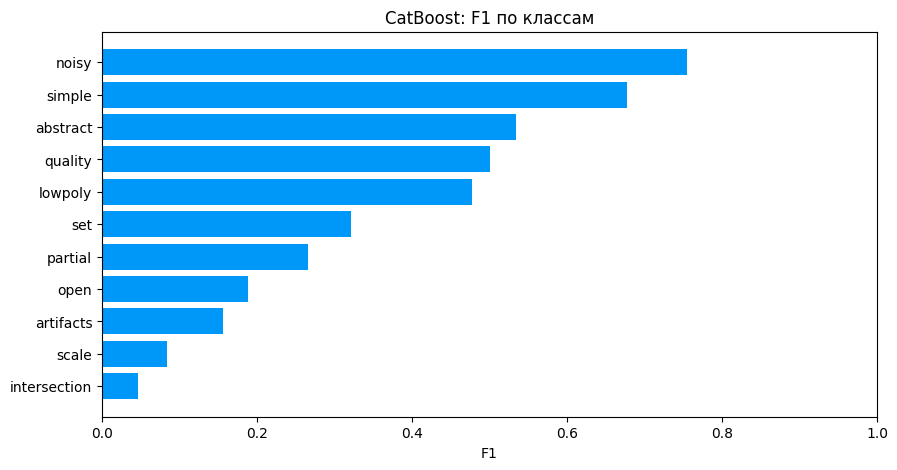

In [12]:
plot_data = error_table.sort_values('F1')

plt.figure(figsize=(10, 5))
plt.barh(plot_data['target'], plot_data['F1'], color='#0098F8')
plt.xlabel('F1')
plt.title('CatBoost: F1 по классам')
plt.xlim(0, 1)
plt.show()


,importance
min_to_max,15.4305
faces_per_vertex,6.9512
surface_area,6.4540
edge_std,5.9284
faces_count,4.4642
edge_max,4.0319
radius_max,3.9077
std_z,3.8824
radius_mean,3.6301
face_area_std,3.5843


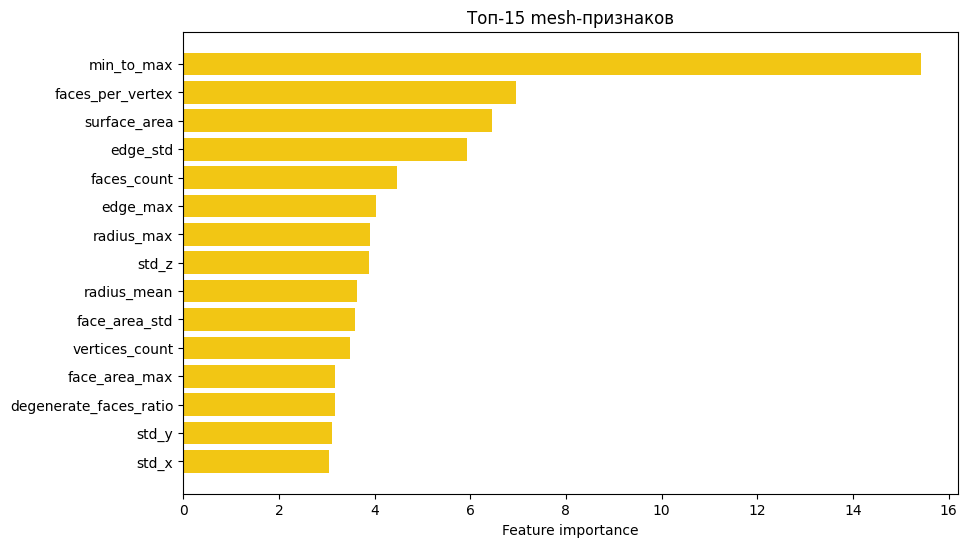

In [13]:
feature_importance = pd.DataFrame({
    target: models[target].get_feature_importance()
    for target in target_columns
}, index=feature_columns)

mean_importance = (
    feature_importance
    .mean(axis=1)
    .sort_values(ascending=False)
    .head(15)
)

display(mean_importance.to_frame('importance').round(4))

plt.figure(figsize=(10, 6))
plt.barh(
    mean_importance.sort_values().index,
    mean_importance.sort_values().values,
    color='#F2C614'
)
plt.xlabel('Feature importance')
plt.title('Топ-15 mesh-признаков')
plt.show()


## 8. Threshold tuning

In [14]:
threshold_grid = np.arange(0.05, 0.96, 0.01)
best_thresholds = []

for column_index in range(len(target_columns)):
    target = val_targets[:, column_index]
    probabilities = val_probabilities[:, column_index]

    scores = [
        f1_score(
            target,
            probabilities >= threshold,
            zero_division=0
        )
        for threshold in threshold_grid
    ]

    best_thresholds.append(
        threshold_grid[np.argmax(scores)]
    )

best_thresholds = np.array(best_thresholds)

pd.DataFrame({
    'target': target_columns,
    'threshold': best_thresholds
}).round(2)


,target,threshold
0,abstract,0.61
1,artifacts,0.62
2,intersection,0.56
3,lowpoly,0.66
4,noisy,0.53
5,open,0.55
6,partial,0.73
7,scale,0.66
8,set,0.59
9,simple,0.53


In [15]:
tuned_class_f1, tuned_weighted_f1, tuned_quality_f1, tuned_score = (
    calculate_metrics(
        val_targets,
        val_probabilities,
        thresholds=best_thresholds
    )
)

pd.DataFrame({
    'variant': ['threshold 0.5', 'tuned thresholds'],
    'macro_f1': [class_f1.mean(), tuned_class_f1.mean()],
    'weighted_f1': [weighted_f1, tuned_weighted_f1],
    'quality_f1': [quality_f1, tuned_quality_f1],
    'score': [score, tuned_score]
}).round(4)


,variant,macro_f1,weighted_f1,quality_f1,score
0,threshold 0.5,0.3642,0.5364,0.5009,0.5186
1,tuned thresholds,0.4059,0.5614,0.5108,0.5361


In [16]:
THRESHOLDS_PATH = ARTIFACTS_DIR / 'catboost_mesh_thresholds.json'

thresholds_to_save = {
    target: float(threshold)
    for target, threshold in zip(target_columns, best_thresholds)
}

with open(THRESHOLDS_PATH, 'w', encoding='utf-8') as file:
    json.dump(thresholds_to_save, file, indent=2)

print('Сохранено:', THRESHOLDS_PATH)


Сохранено: artifacts\catboost_mesh_thresholds.json


## 9. CatBoost ensemble

In [17]:
ensemble_configs = [
    {
        'name': 'depth_5',
        'iterations': 600,
        'depth': 5,
        'learning_rate': 0.04,
        'random_seed': 123
    },
    {
        'name': 'depth_7',
        'iterations': 600,
        'depth': 7,
        'learning_rate': 0.03,
        'random_seed': 777
    }
]

ENSEMBLE_MODELS_DIR = ROOT / 'models' / 'catboost_ensemble'
ENSEMBLE_MODELS_DIR.mkdir(parents=True, exist_ok=True)

ensemble_probabilities = [val_probabilities]


In [18]:
for config in ensemble_configs:
    probabilities = np.zeros(
        (len(val_df), len(target_columns))
    )
    config_dir = ENSEMBLE_MODELS_DIR / config['name']
    config_dir.mkdir(exist_ok=True)

    for column_index, target in enumerate(target_columns):
        model = CatBoostClassifier(
            iterations=config['iterations'],
            depth=config['depth'],
            learning_rate=config['learning_rate'],
            loss_function='Logloss',
            auto_class_weights='Balanced',
            random_seed=config['random_seed'],
            verbose=False,
            allow_writing_files=False
        )

        model.fit(
            X_train,
            train_df[target],
            eval_set=(X_val, val_df[target]),
            early_stopping_rounds=50,
            verbose=False
        )

        probabilities[:, column_index] = (
            model.predict_proba(X_val)[:, 1]
        )
        model.save_model(str(config_dir / f'{target}.cbm'))

    ensemble_probabilities.append(probabilities)
    print('Готово:', config['name'])


Готово: depth_5
Готово: depth_7


## 10. Выбор веса ансамбля

In [19]:
def find_best_thresholds(probabilities):
    thresholds = []

    for column_index in range(len(target_columns)):
        target = val_targets[:, column_index]
        class_probabilities = probabilities[:, column_index]

        scores = [
            f1_score(
                target,
                class_probabilities >= threshold,
                zero_division=0
            )
            for threshold in threshold_grid
        ]

        thresholds.append(threshold_grid[np.argmax(scores)])

    return np.array(thresholds)


alternative_average = np.mean(
    ensemble_probabilities[1:],
    axis=0
)
weight_grid = np.arange(0, 1.01, 0.1)
blend_rows = []

for baseline_weight in weight_grid:
    probabilities = (
        baseline_weight * val_probabilities
        + (1 - baseline_weight) * alternative_average
    )
    thresholds = find_best_thresholds(probabilities)
    metrics = calculate_metrics(
        val_targets,
        probabilities,
        thresholds
    )

    blend_rows.append({
        'baseline_weight': baseline_weight,
        'macro_f1': metrics[0].mean(),
        'weighted_f1': metrics[1],
        'quality_f1': metrics[2],
        'score': metrics[3]
    })

blend_results = pd.DataFrame(blend_rows)
blend_results.round(4)


,baseline_weight,macro_f1,weighted_f1,quality_f1,score
0,0.0,0.4107,0.5646,0.5083,0.5364
1,0.1,0.4109,0.5639,0.5110,0.5374
2,0.2,0.4079,0.5649,0.5118,0.5384
3,0.3,0.4094,0.5639,0.5124,0.5381
4,0.4,0.4061,0.5640,0.5115,0.5377
5,0.5,0.4070,0.5650,0.5143,0.5396
6,0.6,0.4060,0.5627,0.5177,0.5402
7,0.7,0.4030,0.5616,0.5182,0.5399
8,0.8,0.4087,0.5634,0.5213,0.5423
9,0.9,0.4064,0.5622,0.5139,0.5381


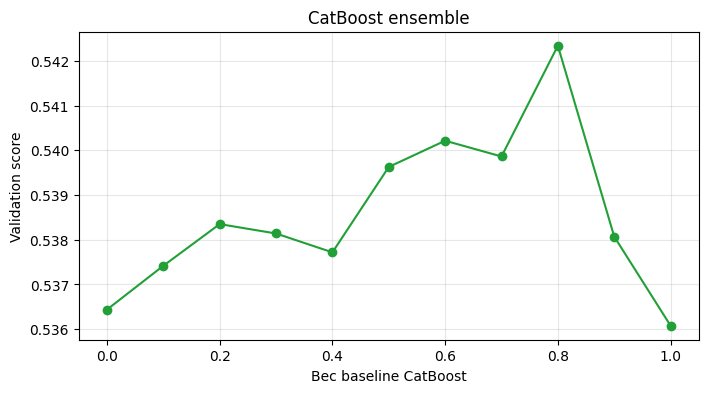

In [20]:
plt.figure(figsize=(8, 4))
plt.plot(
    blend_results['baseline_weight'],
    blend_results['score'],
    marker='o',
    color='#21A038'
)
plt.xlabel('Вес baseline CatBoost')
plt.ylabel('Validation score')
plt.title('CatBoost ensemble')
plt.grid(alpha=0.3)
plt.show()


In [21]:
best_row = blend_results.loc[
    blend_results['score'].idxmax()
]
best_baseline_weight = best_row['baseline_weight']

best_ensemble_probabilities = (
    best_baseline_weight * val_probabilities
    + (1 - best_baseline_weight) * alternative_average
)
best_ensemble_thresholds = find_best_thresholds(
    best_ensemble_probabilities
)
best_ensemble_metrics = calculate_metrics(
    val_targets,
    best_ensemble_probabilities,
    best_ensemble_thresholds
)

comparison = pd.DataFrame({
    'variant': [
        'CatBoost baseline tuned',
        'CatBoost ensemble tuned'
    ],
    'macro_f1': [
        tuned_class_f1.mean(),
        best_ensemble_metrics[0].mean()
    ],
    'weighted_f1': [
        tuned_weighted_f1,
        best_ensemble_metrics[1]
    ],
    'quality_f1': [
        tuned_quality_f1,
        best_ensemble_metrics[2]
    ],
    'score': [
        tuned_score,
        best_ensemble_metrics[3]
    ]
})

print('Лучший вес baseline:', round(best_baseline_weight, 2))
display(comparison.round(4))


Лучший вес baseline: 0.8


,variant,macro_f1,weighted_f1,quality_f1,score
0,CatBoost baseline tuned,0.4059,0.5614,0.5108,0.5361
1,CatBoost ensemble tuned,0.4087,0.5634,0.5213,0.5423


In [22]:
ENSEMBLE_THRESHOLDS_PATH = (
    ARTIFACTS_DIR / 'catboost_ensemble_thresholds.json'
)

thresholds_to_save = {
    target: float(threshold)
    for target, threshold in zip(
        target_columns,
        best_ensemble_thresholds
    )
}

with open(ENSEMBLE_THRESHOLDS_PATH, 'w', encoding='utf-8') as file:
    json.dump(thresholds_to_save, file, indent=2)

print('Сохранено:', ENSEMBLE_THRESHOLDS_PATH)


Сохранено: artifacts\catboost_ensemble_thresholds.json
